Ejercicios prácticos con soluciones para el cálculo y comprensión del impacto de cada capa en una red neuronal, enfocados en:

* Evaluar cómo cada capa afecta el rendimiento
* Medir el impacto en términos de accuracy, tiempo de entrenamiento, y parámetros
* Visualizar el flujo de activaciones y la complejidad del modelo



Objetivo del ejercicio
* Comprender cómo influye cada capa (oculta o de regularización) en el comportamiento de una red neuronal, utilizando Fashion-MNIST como dataset de ejemplo.

Versión Keras (TensorFlow)

In [1]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.datasets import fashion_mnist
import time
import pandas as pd

In [2]:
# Cargar datos
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
# Métricas a registrar
resultados = []

def build_model(layers_config):
    model = Sequential([Flatten(input_shape=(28, 28))])
    for units, dropout in layers_config:
        model.add(Dense(units, activation='relu'))
        if dropout > 0:
            model.add(Dropout(dropout))
    model.add(Dense(10, activation='softmax'))
    return model

In [4]:
# Configuraciones por experimento (cada uno muestra el impacto de una capa más)
experimentos = [
    [ (128, 0.0) ],
    [ (128, 0.0), (64, 0.0) ],
    [ (128, 0.0), (64, 0.0), (32, 0.0) ],
    [ (128, 0.2), (64, 0.3), (32, 0.3) ]
]

for idx, config in enumerate(experimentos):
    print(f"\n🔬 Probando configuración {idx+1}")
    model = build_model(config)
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    start = time.time()
    model.fit(x_train, y_train, epochs=3, batch_size=128, verbose=0)
    tiempo = time.time() - start
    loss, acc = model.evaluate(x_test, y_test, verbose=0)

    resultados.append({
        "Configuración": f"{[u for u,_ in config]}",
        "Dropouts": f"{[d for _,d in config]}",
        "Capas Ocultas": len(config),
        "Parámetros": model.count_params(),
        "Accuracy": round(acc, 4),
        "Tiempo (s)": round(tiempo, 2)
    })


🔬 Probando configuración 1


/usr/local/lib/python3.11/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



🔬 Probando configuración 2

🔬 Probando configuración 3

🔬 Probando configuración 4


In [5]:
# Mostrar tabla
df_resultados = pd.DataFrame(resultados)
print(df_resultados)

   Configuración         Dropouts  Capas Ocultas  Parámetros  Accuracy  \
0          [128]            [0.0]              1      101770    0.8594   
1      [128, 64]       [0.0, 0.0]              2      109386    0.8583   
2  [128, 64, 32]  [0.0, 0.0, 0.0]              3      111146    0.8648   
3  [128, 64, 32]  [0.2, 0.3, 0.3]              3      111146    0.8462   

   Tiempo (s)  
0        7.46  
1        8.00  
2        9.84  
3        9.95  


Versión PyTorch

In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import time
import pandas as pd

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [8]:
# Cargar dataset
transform = transforms.ToTensor()
trainset = torchvision.datasets.FashionMNIST('./data', train=True, download=True, transform=transform)
testset = torchvision.datasets.FashionMNIST('./data', train=False, download=True, transform=transform)

trainloader = DataLoader(trainset, batch_size=128, shuffle=True)
testloader = DataLoader(testset, batch_size=1000)

100%|██████████| 26.4M/26.4M [00:01<00:00, 18.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 273kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.05MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 22.4MB/s]


In [10]:
resultados = []

In [11]:
class CustomNet(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.flatten = nn.Flatten()
        self.hidden = nn.ModuleList()
        self.dropouts = nn.ModuleList()
        in_dim = 28*28
        for out_dim, dropout in config:
            self.hidden.append(nn.Linear(in_dim, out_dim))
            self.dropouts.append(nn.Dropout(dropout))
            in_dim = out_dim
        self.output = nn.Linear(in_dim, 10)

    def forward(self, x):
        x = self.flatten(x)
        for h, d in zip(self.hidden, self.dropouts):
            x = F.relu(h(x))
            x = d(x)
        return self.output(x)

In [12]:
experimentos = [
    [ (128, 0.0) ],
    [ (128, 0.0), (64, 0.0) ],
    [ (128, 0.0), (64, 0.0), (32, 0.0) ],
    [ (128, 0.2), (64, 0.3), (32, 0.3) ]
]

In [13]:
criterion = nn.CrossEntropyLoss()

In [14]:
for idx, config in enumerate(experimentos):
    print(f"\n🔬 Configuración {idx+1}")
    model = CustomNet(config).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    start = time.time()
    model.train()
    for epoch in range(3):
        for inputs, targets in trainloader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
    duracion = time.time() - start

    model.eval()
    correctos = total = 0
    with torch.no_grad():
        for inputs, targets in testloader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            _, pred = outputs.max(1)
            correctos += pred.eq(targets).sum().item()
            total += targets.size(0)
    acc = correctos / total
    resultados.append({
        "Configuración": f"{[u for u,_ in config]}",
        "Dropouts": f"{[d for _,d in config]}",
        "Capas Ocultas": len(config),
        "Parámetros": sum(p.numel() for p in model.parameters()),
        "Accuracy": round(acc, 4),
        "Tiempo (s)": round(duracion, 2)
    })


🔬 Configuración 1

🔬 Configuración 2

🔬 Configuración 3

🔬 Configuración 4


In [15]:
df = pd.DataFrame(resultados)
print(df)

   Configuración         Dropouts  Capas Ocultas  Parámetros  Accuracy  \
0          [128]            [0.0]              1      101770    0.8564   
1      [128, 64]       [0.0, 0.0]              2      109386    0.8570   
2  [128, 64, 32]  [0.0, 0.0, 0.0]              3      111146    0.8566   
3  [128, 64, 32]  [0.2, 0.3, 0.3]              3      111146    0.8504   

   Tiempo (s)  
0       24.87  
1       26.64  
2       25.77  
3       26.41  


Realizar tabla comarativa como la siguiente a partir de diferentes configuraciones:

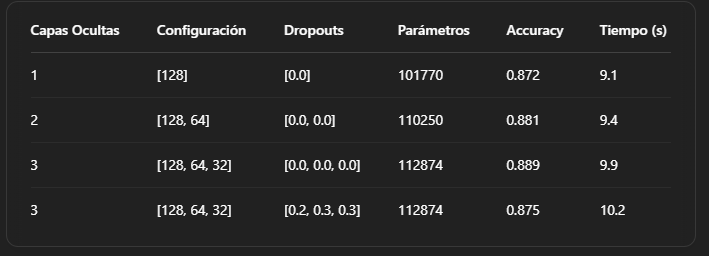

¿Qué se observa?

* Aumentar capas mejora el rendimiento hasta cierto punto.
* El Dropout previene overfitting, pero puede afectar la precisión si es muy alto.
* Más capas implican más tiempo de entrenamiento y parámetros a ajustar.